# Error analysis by spoiler type

Where do the systems go wrong, and is it the same for prompted and fine-tuned models? This notebook looks at four systems on the 1,000 test posts:
- **RoBERTa-base QA**, the Milestone 2 strong baseline (extractive);
- **Llama 3.1 8B fine-tuned with QLoRA**, our best fine-tuned model (Milestone 3);
- **Claude Sonnet 5.5** and **GPT-6.1 Sol**, the two best prompted LLMs (`1-prompted-llms.ipynb`).

Edit `ANALYZED` in the setup cell to look at other systems. Like `2-compare.ipynb` it only reads files and runs in about a minute.

**Sections:**
1. **How each system answers:** type shares, number of spoilers, length, copying (all systems).
2. **Wrong types:** confusion matrices, and what a wrong type costs.
3. **Phrase and passage errors:** is the answer exact, too long, too short, partly overlapping, or a miss?
4. **Multi errors:** how many of the gold items are found, and is the count right?
5. **Length:** BLEU by gold spoiler length.
6. **Where the spoiler is:** BLEU by the spoiler's position and the article's length.
7. **Platform:** BLEU by where the post was published.
8. **Posts nobody gets right** and **where prompted and fine-tuned disagree**, with examples.

Tables go to `output/errors-*.csv` and `.md`, the chart to `output/figures/`.

## Setup

The same setup as `2-compare.ipynb` (systems, predictions, per-post BLEU), then one table with a row per (system, post): gold and predicted type, BLEU, the spoiler items, their lengths, the error category, and facts about the post (platform, article length, where the gold spoiler starts).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from spoilerqa import compare as C
from spoilerqa import llm
from spoilerqa.data import DEFAULT_DATA_DIR, TYPES, build_context, load_jsonl, load_split, post_text, spoiler_type
from spoilerqa.metrics import as_text, ensure_nltk_data
from spoilerqa.tables import to_markdown

ensure_nltk_data()
pd.set_option("display.max_colwidth", 90)

DATA_DIR = Path(os.environ.get("DATA_DIR", DEFAULT_DATA_DIR))
OUTPUT_DIR = Path("../output")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROJECT_ROOT = Path.cwd().resolve().parents[1]

print("fine-tuned files copied into output/finetuned/:", C.collect_finetuned(PROJECT_ROOT, OUTPUT_DIR))
SYSTEMS = C.systems(OUTPUT_DIR)
BY_KEY = {s["key"]: s for s in SYSTEMS}
test = load_split(DATA_DIR, "test")
gold = {r["uuid"]: r for r in test}
preds = {s["key"]: C.load_preds(s["pred"]) for s in SYSTEMS}
scores = {s["key"]: C.load_scores(s["scores"]) for s in SYSTEMS}
bleu = {s["key"]: C.per_post_bleu(test, preds[s["key"]]) for s in SYSTEMS}


def save_table(df, name, digits=4):
    # Every table is written as CSV (for further analysis) and as markdown (for the report notes).
    df.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    (OUTPUT_DIR / f"{name}.md").write_text(to_markdown(df, digits=digits))


# Chart colors: color = kind of system; text stays in neutral ink.
FAMILY_COLORS = {"baseline": "#8a8984", "fine-tuned": "#2a78d6", "prompted": "#eb6834"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # categorical slots, always in this order
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"


def style_axis(ax, grid_axis="x"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(colors=INK_2, labelsize=8.5)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(INK_2)


display(pd.DataFrame([{"system": s["label"], "kind": s["family"], "size": s["size"],
                       "worked examples": s.get("k", ""), "predictions": str(s["pred"].relative_to(OUTPUT_DIR))}
                      for s in SYSTEMS]))


ANALYZED = ["roberta-base-qa", "llama-qlora", "claude-sonnet-5.5", "gpt-6.1-sol"]
ANALYZED = [k for k in ANALYZED if k in BY_KEY]
LABEL = {k: BY_KEY[k]["short"] for k in BY_KEY}

/opt/anaconda3/envs/NLP/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fine-tuned files copied into output/finetuned/: 0


,system,kind,size,worked examples,predictions
0,Simple baseline (first sentence),baseline,-,,finetuned/predictions/simple-baseline-test.jsonl
1,RoBERTa-base QA (M2 strong baseline),fine-tuned,125M,,finetuned/predictions/strong-baseline-test.jsonl
2,DeBERTa-v3-large QA,fine-tuned,435M,,finetuned/predictions/deberta-qa-test.jsonl
3,Flan-T5-large,fine-tuned,783M,,finetuned/predictions/flan-t5-test.jsonl
4,"Llama 3.1 8B, fine-tuned (QLoRA)",fine-tuned,8B (42M trained),,finetuned/predictions/llama-qlora-test.jsonl
5,"Llama 3.1 8B, prompted",prompted,8B (4-bit),0,predictions/llama3.1-8b_article_k0_test.jsonl
6,GPT-OSS 20B,prompted,21B MoE (4-bit),0,predictions/gpt-oss-20b_article_k0_test.jsonl
7,Claude Sonnet 5.5,prompted,not disclosed,6,predictions/claude-sonnet-5.5_article_k6_test.jsonl
8,Claude Haiku 5.5,prompted,not disclosed,3,predictions/claude-haiku-5.5_article_k3_test.jsonl
9,GPT-6.1 Sol,prompted,not disclosed,6,predictions/gpt-6.1-sol_article_k6_test.jsonl


In [2]:
from spoilerqa.data import spoiler_offsets


def first_offset(record):
    # character offset where the first locatable gold span starts in the context (title + paragraphs)
    offsets, _ = spoiler_offsets(record)
    starts = [o[0] for o in offsets if o]
    return min(starts) if starts else None


post_facts = {}
for r in test:
    title_len = len(r["targetTitle"])
    start = first_offset(r)
    post_facts[r["uuid"]] = {"platform": r["postPlatform"], "article chars": len(build_context(r)),
                             "spoiler start": start, "in title": start is not None and start < title_len,
                             "promised count": C.promised_count(post_text(r))}

rows = []
for key in BY_KEY:
    for u, p in preds[key].items():
        g = gold[u]
        gold_items, pred_items = g["spoiler"], C.items(p["spoiler"])
        row = {"system": key, "uuid": u, "gold type": spoiler_type(g), "predicted type": p["spoilerType"],
               "BLEU": float(bleu[key][u]), "gold items": len(gold_items), "predicted items": len(pred_items),
               "gold words": C.word_count(as_text(gold_items)), "predicted words": C.word_count(as_text(pred_items)),
               **post_facts[u]}
        if spoiler_type(g) == "multi":
            found, correct = C.multi_match(gold_items, pred_items)
            row.update({"gold items found": found, "predicted items correct": correct, "category": None})
        else:
            row["category"] = C.span_category(gold_items[0], as_text(pred_items))
        rows.append(row)
posts = pd.DataFrame(rows)
posts["type right"] = posts["gold type"] == posts["predicted type"]
focus = posts[posts["system"].isin(ANALYZED)]
print(f"{len(posts)} (system, post) rows; analyzed systems: {[LABEL[k] for k in ANALYZED]}")

11000 (system, post) rows; analyzed systems: ['RoBERTa-base QA', 'Llama 8B fine-tuned', 'Claude Sonnet 5.5', 'GPT-6.1 Sol']


## 1. How each system answers (all systems)

A profile of every system's answers on test, next to the gold annotations:
- **predicted phrase / passage / multi:** the share of posts given each type;
- **items per multi answer:** mean number of spoilers when the system predicts multi (gold multi posts have 2–5 items);
- **words, phrase / passage:** median answer length on gold phrase and gold passage posts;
- **zero BLEU:** share of posts whose answer shares no word with the gold spoiler.

In [3]:
profile_rows = []
for key in BY_KEY:
    d = posts[posts["system"] == key]
    profile_rows.append({"system": BY_KEY[key]["label"], "kind": BY_KEY[key]["family"],
                         **{f"predicted {t}": float((d["predicted type"] == t).mean()) for t in TYPES},
                         "items per multi answer": float(d.loc[d["predicted type"] == "multi", "predicted items"].mean()),
                         "words, phrase": float(d.loc[d["gold type"] == "phrase", "predicted words"].median()),
                         "words, passage": float(d.loc[d["gold type"] == "passage", "predicted words"].median()),
                         "zero BLEU": float((d["BLEU"] == 0).mean())})
base = posts[posts["system"] == ANALYZED[0]]
profile_rows.append({"system": "gold", "kind": "", **{f"predicted {t}": float((base["gold type"] == t).mean()) for t in TYPES},
                     "items per multi answer": float(base.loc[base["gold type"] == "multi", "gold items"].mean()),
                     "words, phrase": float(base.loc[base["gold type"] == "phrase", "gold words"].median()),
                     "words, passage": float(base.loc[base["gold type"] == "passage", "gold words"].median()), "zero BLEU": None})
profile = pd.DataFrame(profile_rows)
save_table(profile, "errors-profile", digits=3)
profile.style.format(precision=3, na_rep="")

,system,kind,predicted phrase,predicted passage,predicted multi,items per multi answer,"words, phrase","words, passage",zero BLEU
0,Simple baseline (first sentence),baseline,1.000,0.000,0.000,,18.000,18.000,0.544
1,RoBERTa-base QA (M2 strong baseline),fine-tuned,0.400,0.395,0.205,5.000,2.000,11.000,0.169
2,DeBERTa-v3-large QA,fine-tuned,0.400,0.395,0.205,5.000,2.000,13.000,0.137
3,Flan-T5-large,fine-tuned,0.389,0.474,0.137,4.234,2.000,22.000,0.136
4,"Llama 3.1 8B, fine-tuned (QLoRA)",fine-tuned,0.433,0.413,0.154,3.838,2.000,20.000,0.111
5,"Llama 3.1 8B, prompted",prompted,0.138,0.707,0.155,9.613,9.000,17.000,0.310
6,GPT-OSS 20B,prompted,0.800,0.132,0.068,6.912,2.000,6.000,0.256
7,Claude Sonnet 5.5,prompted,0.419,0.450,0.131,4.206,3.000,24.000,0.093
8,Claude Haiku 5.5,prompted,0.289,0.583,0.128,4.508,5.000,21.000,0.160
9,GPT-6.1 Sol,prompted,0.421,0.459,0.120,4.300,3.000,20.000,0.104


## 2. Wrong types

**Confusion matrices** (rows: gold type, columns: predicted type) for the analyzed systems, then **what a wrong type costs**: mean BLEU per gold type when the predicted type is right and when it is wrong, and the share of posts of that type that get a wrong type.

The type matters because it decides the answer's shape: a passage-sized answer to a phrase post (or one item instead of five) loses most of its BLEU even when it contains the right text.

In [4]:
for key in ANALYZED:
    d = focus[focus["system"] == key]
    print(LABEL[key])
    display(pd.crosstab(d["gold type"], d["predicted type"]).reindex(index=TYPES, columns=TYPES, fill_value=0))

cost_rows = []
for key in ANALYZED:
    d = focus[focus["system"] == key]
    for t in TYPES:
        dt = d[d["gold type"] == t]
        cost_rows.append({"system": LABEL[key], "gold type": t, "posts": len(dt),
                          "wrong type": float((~dt["type right"]).mean()),
                          "BLEU, type right": float(dt.loc[dt["type right"], "BLEU"].mean()),
                          "BLEU, type wrong": float(dt.loc[~dt["type right"], "BLEU"].mean())})
type_cost = pd.DataFrame(cost_rows)
save_table(type_cost, "errors-type-cost", digits=3)
type_cost.style.format(precision=3, na_rep="")

RoBERTa-base QA


predicted type,phrase,passage,multi
gold type,,,
phrase,296,81,46
passage,74,286,43
multi,30,28,116


Llama 8B fine-tuned


predicted type,phrase,passage,multi
gold type,,,
phrase,337,71,15
passage,66,318,19
multi,30,24,120


Claude Sonnet 5.5


predicted type,phrase,passage,multi
gold type,,,
phrase,334,80,9
passage,59,327,17
multi,26,43,105


GPT-6.1 Sol


predicted type,phrase,passage,multi
gold type,,,
phrase,344,74,5
passage,53,339,11
multi,24,46,104


,system,gold type,posts,wrong type,"BLEU, type right","BLEU, type wrong"
0,RoBERTa-base QA,phrase,423,0.300,0.700,0.269
1,RoBERTa-base QA,passage,403,0.290,0.259,0.132
2,RoBERTa-base QA,multi,174,0.333,0.382,0.160
3,Llama 8B fine-tuned,phrase,423,0.203,0.768,0.177
4,Llama 8B fine-tuned,passage,403,0.211,0.395,0.258
5,Llama 8B fine-tuned,multi,174,0.310,0.606,0.235
6,Claude Sonnet 5.5,phrase,423,0.210,0.724,0.094
7,Claude Sonnet 5.5,passage,403,0.189,0.441,0.344
8,Claude Sonnet 5.5,multi,174,0.397,0.490,0.222
9,GPT-6.1 Sol,phrase,423,0.187,0.767,0.108


## 3. Phrase and passage: what kind of error?

Phrase and passage posts have one gold span. Each answer falls into one category (`spoilerqa/compare.py: span_category`), comparing text with case, punctuation and spacing ignored:
- **exact:** the gold text;
- **contains gold (too long):** the gold text plus extra words;
- **inside gold (too short):** part of the gold text;
- **partial overlap:** shares words with the gold text, but neither contains the other;
- **miss:** no word in common (a different part of the article, or an invented answer).

The table gives the share of each category and the mean BLEU within it. The chart shows the shares, saved as `output/figures/errors-span-categories.png`.

,system,gold type,posts,exact,contains gold (too long),inside gold (too short),partial overlap,miss,"BLEU, exact","BLEU, contains gold (too long)","BLEU, inside gold (too short)","BLEU, partial overlap","BLEU, miss"
0,RoBERTa-base QA,phrase,423,0.504,0.206,0.087,0.047,0.156,0.949,0.233,0.508,0.000,0.000
1,RoBERTa-base QA,passage,403,0.092,0.117,0.243,0.385,0.164,0.983,0.385,0.276,0.051,0.000
2,Llama 8B fine-tuned,phrase,423,0.584,0.154,0.069,0.066,0.128,0.960,0.299,0.537,0.076,0.000
3,Llama 8B fine-tuned,passage,403,0.189,0.203,0.171,0.357,0.079,0.983,0.484,0.392,0.042,0.000
4,Claude Sonnet 5.5,phrase,423,0.475,0.326,0.035,0.052,0.111,0.972,0.338,0.464,0.045,0.000
5,Claude Sonnet 5.5,passage,403,0.223,0.283,0.122,0.330,0.042,0.983,0.466,0.409,0.064,0.000
6,GPT-6.1 Sol,phrase,423,0.556,0.248,0.033,0.045,0.118,0.958,0.388,0.464,0.000,0.000
7,GPT-6.1 Sol,passage,403,0.248,0.256,0.161,0.295,0.040,0.986,0.517,0.343,0.037,0.000


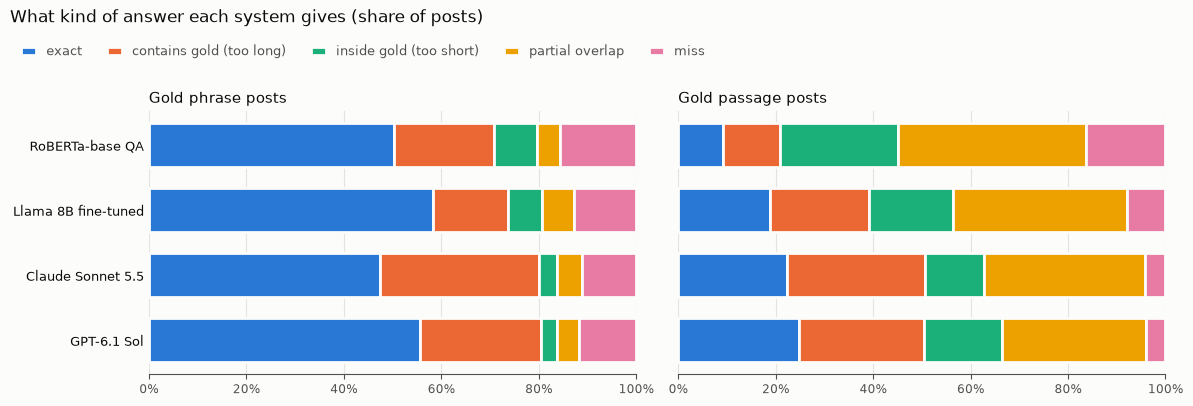

In [5]:
span = focus[focus["gold type"] != "multi"]
category_rows = []
for key in ANALYZED:
    for t in ("phrase", "passage"):
        d = span[(span["system"] == key) & (span["gold type"] == t)]
        row = {"system": LABEL[key], "gold type": t, "posts": len(d)}
        for c in C.SPAN_CATEGORIES:
            row[c] = float((d["category"] == c).mean())
        for c in C.SPAN_CATEGORIES:
            row[f"BLEU, {c}"] = float(d.loc[d["category"] == c, "BLEU"].mean()) if (d["category"] == c).any() else None
        category_rows.append(row)
categories = pd.DataFrame(category_rows)
save_table(categories, "errors-span-categories", digits=3)
display(categories.style.format(precision=3, na_rep=""))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, facecolor=SURFACE)
for ax, t in zip(axes, ("phrase", "passage")):
    d = categories[categories["gold type"] == t].iloc[::-1]
    left = np.zeros(len(d))
    style_axis(ax)
    for j, c in enumerate(C.SPAN_CATEGORIES):
        ax.barh(np.arange(len(d)), d[c], left=left, height=0.68, color=SERIES[j], edgecolor=SURFACE, linewidth=2,
                label=c, zorder=2)
        left += d[c].to_numpy()
    ax.set_yticks(np.arange(len(d)), d["system"], color=INK, fontsize=9)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(f"Gold {t} posts", loc="left", color=INK, fontsize=11)
fig.text(0.01, 1.08, "What kind of answer each system gives (share of posts)", color=INK, fontsize=12, ha="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.01, 1.05), ncol=5,
           frameon=False, fontsize=9, labelcolor=INK_2, handlelength=1.2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG_DIR / "errors-span-categories.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
plt.show()

## 4. Multi posts: items found and item counts

A multi spoiler has 2–5 separate items. Each predicted item is matched to the gold items by SQuAD token F1 ≥ 0.5 (`compare.multi_match`):
- **gold items found:** the share of gold items that some predicted item matches (recall);
- **predicted items correct:** the share of predicted items that match a gold item (precision);
- **all found / none found:** posts where every gold item, or none, is found;
- **fewer / same / more items:** the answer's item count against the gold count.

**Promised counts.** Many multi posts promise a number ("5 ways to ..."). For those, the last column gives how often the answer has exactly that many items (the gold annotations stop at 5, so promises above 5 count as 5).

In [6]:
multi = focus[focus["gold type"] == "multi"]
multi_rows = []
for key in ANALYZED:
    d = multi[multi["system"] == key]
    promised = d[d["promised count"].notna()]
    multi_rows.append({
        "system": LABEL[key], "posts": len(d),
        "gold items found": float(d["gold items found"].sum() / d["gold items"].sum()),
        "predicted items correct": float(d["predicted items correct"].sum() / max(d["predicted items"].sum(), 1)),
        "all found": float((d["gold items found"] == d["gold items"]).mean()),
        "none found": float((d["gold items found"] == 0).mean()),
        "fewer items": float((d["predicted items"] < d["gold items"]).mean()),
        "same count": float((d["predicted items"] == d["gold items"]).mean()),
        "more items": float((d["predicted items"] > d["gold items"]).mean()),
        "posts with a promised count": len(promised),
        "count = promise": float((promised["predicted items"] == promised["promised count"].clip(upper=5)).mean()) if len(promised) else None,
    })
multi_table = pd.DataFrame(multi_rows)
save_table(multi_table, "errors-multi", digits=3)
multi_table.style.format(precision=3, na_rep="")

,system,posts,gold items found,predicted items correct,all found,none found,fewer items,same count,more items,posts with a promised count,count = promise
0,RoBERTa-base QA,174,0.587,0.597,0.316,0.195,0.316,0.448,0.236,59,0.729
1,Llama 8B fine-tuned,174,0.697,0.788,0.460,0.178,0.351,0.598,0.052,59,0.814
2,Claude Sonnet 5.5,174,0.620,0.730,0.368,0.253,0.397,0.529,0.075,59,0.814
3,GPT-6.1 Sol,174,0.617,0.721,0.402,0.247,0.420,0.523,0.057,59,0.780


## 5. Length: BLEU by gold spoiler length

Mean BLEU per bucket of gold spoiler length (words), for phrase and passage posts. Long passage spoilers are the hardest case for every system; this shows whether the prompted and fine-tuned models fail on different lengths.

In [7]:
BUCKETS = {"phrase": [0, 1, 3, 5, 1000], "passage": [0, 10, 20, 40, 1000]}
length_rows = []
for t, edges in BUCKETS.items():
    d = focus[focus["gold type"] == t].copy()
    names = [f"> {a}" if b >= 1000 else str(b) if a + 1 == b else f"{a + 1}-{b}" for a, b in zip(edges, edges[1:])]
    d["gold length"] = pd.cut(d["gold words"], edges, labels=names)
    table = d.pivot_table(index="gold length", columns="system", values="BLEU", aggfunc="mean", observed=False)[ANALYZED]
    counts = d[d["system"] == ANALYZED[0]].groupby("gold length", observed=False).size()
    for bucket in table.index:
        length_rows.append({"gold type": t, "gold words": str(bucket), "posts": int(counts[bucket]),
                            **{LABEL[k]: table.loc[bucket, k] for k in ANALYZED}})
lengths = pd.DataFrame(length_rows)
save_table(lengths, "errors-length", digits=3)
lengths.style.format(precision=3, na_rep="")

,gold type,gold words,posts,RoBERTa-base QA,Llama 8B fine-tuned,Claude Sonnet 5.5,GPT-6.1 Sol
0,phrase,1,107,0.659,0.760,0.642,0.683
1,phrase,2-3,226,0.586,0.682,0.617,0.681
2,phrase,4-5,78,0.470,0.442,0.456,0.507
3,phrase,> 5,12,0.136,0.359,0.528,0.476
4,passage,1-10,92,0.211,0.310,0.312,0.390
5,passage,11-20,136,0.248,0.367,0.401,0.458
6,passage,21-40,137,0.231,0.420,0.498,0.480
7,passage,> 40,38,0.124,0.298,0.494,0.383


## 6. Where the spoiler is: position and article length

The fine-tuned models read limited windows: the QA models slide over the whole article in 384-token windows, while the fine-tuned Llama only sees the first 1,600 tokens (about 6,000–7,000 characters) of the article. The prompted LLMs read up to 24,000 characters. So:
- **spoiler start:** where the first gold span begins in the title + article text, in characters ("title" when it is in the title);
- **article length:** the total length of the title + article text.

Mean BLEU per bucket, with the number of posts.

In [8]:
def bucket_table(column, edges, labels, name, title_bucket=False):
    d = focus[focus[column].notna()].copy()
    d["bucket"] = pd.cut(d[column], edges, labels=labels, right=False)
    if title_bucket:  # spoilers inside the title get their own bucket, whatever their offset
        d["bucket"] = d["bucket"].cat.add_categories(["title"]).where(~d["in title"], "title")
        d["bucket"] = d["bucket"].cat.reorder_categories(["title", *labels])
    table = d.pivot_table(index="bucket", columns="system", values="BLEU", aggfunc="mean", observed=False)[ANALYZED]
    counts = d[d["system"] == ANALYZED[0]].groupby("bucket", observed=False).size()
    out = pd.DataFrame([{name: str(b), "posts": int(counts[b]), **{LABEL[k]: table.loc[b, k] for k in ANALYZED}} for b in table.index])
    return out


position = bucket_table("spoiler start", [0, 1000, 3000, 6000, 10**7], ["< 1,000", "1,000-3,000", "3,000-6,000", ">= 6,000"],
                        "spoiler start (characters)", title_bucket=True)
article = bucket_table("article chars", [0, 2000, 4000, 7000, 12000, 10**7],
                       ["< 2,000", "2,000-4,000", "4,000-7,000", "7,000-12,000", ">= 12,000"], "article length (characters)")
save_table(position, "errors-position", digits=3)
save_table(article, "errors-article-length", digits=3)
display(position.style.format(precision=3, na_rep=""))
article.style.format(precision=3, na_rep="")

,spoiler start (characters),posts,RoBERTa-base QA,Llama 8B fine-tuned,Claude Sonnet 5.5,GPT-6.1 Sol
0,title,19,0.145,0.307,0.380,0.378
1,"< 1,000",748,0.429,0.554,0.516,0.543
2,"1,000-3,000",189,0.284,0.408,0.431,0.468
3,"3,000-6,000",36,0.195,0.264,0.297,0.287
4,">= 6,000",8,0.009,0.074,0.210,0.323


,article length (characters),posts,RoBERTa-base QA,Llama 8B fine-tuned,Claude Sonnet 5.5,GPT-6.1 Sol
0,"< 2,000",460,0.408,0.552,0.549,0.568
1,"2,000-4,000",292,0.380,0.465,0.442,0.487
2,"4,000-7,000",180,0.367,0.480,0.452,0.483
3,"7,000-12,000",57,0.317,0.492,0.396,0.377
4,">= 12,000",11,0.149,0.272,0.133,0.237


## 7. Platform

The posts come from Twitter, Reddit and Facebook. Mean BLEU per platform, and the share of multi posts on each (multi is the hardest type, so the mix matters).

In [9]:
platform = focus.pivot_table(index="platform", columns="system", values="BLEU", aggfunc="mean")[ANALYZED]
base = focus[focus["system"] == ANALYZED[0]]
platform_table = pd.DataFrame([{"platform": p, "posts": int((base["platform"] == p).sum()),
                                "multi share": float((base.loc[base["platform"] == p, "gold type"] == "multi").mean()),
                                **{LABEL[k]: platform.loc[p, k] for k in ANALYZED}} for p in platform.index])
save_table(platform_table, "errors-platform", digits=3)
platform_table.style.format(precision=3)

,platform,posts,multi share,RoBERTa-base QA,Llama 8B fine-tuned,Claude Sonnet 5.5,GPT-6.1 Sol
0,Facebook,174,0.080,0.388,0.468,0.494,0.509
1,Twitter,482,0.245,0.420,0.561,0.510,0.552
2,reddit,344,0.122,0.333,0.451,0.451,0.465


## 8. Posts nobody gets right, and where prompted and fine-tuned disagree

**Nobody right:** posts where all analyzed systems score 0 BLEU, per gold type, with a sample. Reading them shows whether these are hard posts, vague posts, or annotation problems (for example a gold span that doesn't really answer the post).

In [10]:
wide = focus.pivot_table(index="uuid", columns="system", values="BLEU")[ANALYZED]
nobody = wide[(wide == 0).all(axis=1)].index
by_type = pd.Series([spoiler_type(gold[u]) for u in nobody]).value_counts().reindex(TYPES, fill_value=0)
print(f"{len(nobody)} posts get 0 BLEU from all {len(ANALYZED)} systems:", by_type.to_dict())
sample = pd.Series(nobody).sample(min(8, len(nobody)), random_state=0)
pd.DataFrame([{"post": post_text(gold[u]), "gold type": spoiler_type(gold[u]), "gold": as_text(gold[u]["spoiler"]),
               **{LABEL[k]: as_text(preds[k][u]["spoiler"])[:160] for k in ANALYZED}} for u in sample])

28 posts get 0 BLEU from all 4 systems: {'phrase': 15, 'passage': 12, 'multi': 1}


,post,gold type,gold,RoBERTa-base QA,Llama 8B fine-tuned,Claude Sonnet 5.5,GPT-6.1 Sol
0,"He Did It Again: With Only Months Left, Obama Makes HUGE Move To Fix The World",phrase,join the Paris accord,U.S. and China announced a major agreement to reduce carbon emissions and combat clima...,U.S. and China announced a major agreement to reduce carbon emissions and combat clima...,the U.S. and China announced a major agreement to reduce carbon emissions and combat c...,the U.S. and China announced a major agreement to reduce carbon emissions and combat c...
1,Should we wipe mosquitoes off the face of the Earth?,passage,"""Keep their DNA for future research,"" he writes, ""and let them go.""",can’t we wipe them off the face of the Earth?,"In reality, as Lindsay and Ranson are quick to point out, the total extinction of all ...","In reality, as Lindsay and Ranson are quick to point out, the total extinction of all ...","In reality, as Lindsay and Ranson are quick to point out, the total extinction of all ..."
2,"That 'S' Thing Everyone Drew in School, WHAT IS IT?",phrase,no one knows its origins,Moebius strip,it's fun to draw,"The S isn't a Stussy logo or a Superman emblem or a gift from aliens, I think it's jus...",a Moebius strip
3,How Elizabeth Warren's own book makes the case she should run for president,passage,"""I am determined -- fiercely determined -- to do everything I can to help us once agai...",A Fighting Chance,"A Fighting Chance, shouldn't take from it a very powerful argument for why Warren shou...","All through the book, despite her Shermanesque declarations of non-intent, can be foun...","All through the book, despite her Shermanesque declarations of non-intent, can be foun..."
4,Is This a Time Traveler at a Mike Tyson Fight in 1995?,passage,that probably wasn’t a time traveler,no,The simple answer is no. And the complex answer is also no.,The simple answer is no. And the complex answer is also no.,The simple answer is no. And the complex answer is also no.
5,Are people actually reading your content?,passage,we typically read the page in a F-pattern that puts the most emphasis on the headline ...,2. Follow The Inverted Pyramid Model When You Write,How do you make sure that people are actually reading your content?,"On some posts, many readers didn’t make it past reading 20-30% of our content. Only 10...",Only 10-20% of readers actually make it to the bottom of the post.
6,Guess How Many Zika Cases Showed Up At The Olympics?,phrase,no laboratory confirmed cases,Zero,Zero,Zero.,Zero.
7,"Instead Of Paying Someone $1000 To Remove A Tree Stump, He Drills Into The Center To D...",phrase,set it on fire,"If you have a stump to remove, go grab your largest drill bit (half an inch), a drill,...","Drill holes spaced about two inches apart into the stump as far down as you can go, an...","Drill holes spaced about two inches apart into the stump as far down as you can go, an...","Drill holes spaced about two inches apart into the stump as far down as you can go, an..."


**Prompted vs fine-tuned:** posts where the best prompted model (GPT-6.1 Sol) and the best fine-tuned model (Llama 3.1 8B, QLoRA) differ by at least 0.5 BLEU: how many each way per gold type, and the four largest each way.

In [11]:
a, b = "gpt-6.1-sol", "llama-qlora"
if a in BY_KEY and b in BY_KEY:
    diff = (bleu[a] - bleu[b]).dropna()
    big = diff[diff.abs() >= 0.5]
    counts = pd.crosstab(pd.Series([spoiler_type(gold[u]) for u in big.index], name="gold type"),
                         pd.Series(np.where(big > 0, f"{LABEL[a]} better", f"{LABEL[b]} better"), name="")).reindex(TYPES, fill_value=0)
    save_table(counts.reset_index(), "errors-disagreements", digits=0)
    display(counts)
    picks = list(big.sort_values().index[-4:][::-1]) + list(big.sort_values().index[:4])
    display(pd.DataFrame([{"post": post_text(gold[u]), "gold type": spoiler_type(gold[u]), "gold": as_text(gold[u]["spoiler"]),
                           LABEL[a]: f"[{preds[a][u]['spoilerType']}] {as_text(preds[a][u]['spoiler'])}"[:200],
                           LABEL[b]: f"[{preds[b][u]['spoilerType']}] {as_text(preds[b][u]['spoiler'])}"[:200],
                           "BLEU difference": round(float(diff[u]), 3)} for u in picks]))

,GPT-6.1 Sol better,Llama 8B fine-tuned better
gold type,,
phrase,41,40
passage,60,36
multi,11,30


,post,gold type,gold,GPT-6.1 Sol,Llama 8B fine-tuned,BLEU difference
0,"According to Guys, This Is the Most Overrated Sex Position",passage,"Turns out, men are pretty divided and have ~thoughts~ on every position.","[passage] Turns out, men are pretty divided and have ~thoughts~ on every position.",[phrase] missionary,1.0
1,Singer's father stabbed in critical condition,phrase,Mary J. Blige,[phrase] Mary J. Blige,[phrase] Thomas Blige,1.0
2,The most innovative companies of 2015:,multi,Warby Parker Apple Alibaba Group Google Instagram,[multi] Warby Parker Apple Alibaba Group Google Instagram,[multi] 01 Warby Parker 02 Apple 03 Alibaba Group 04 Google 05 Instagram,1.0
3,Heres the world record for beating fallout 4 as fast as possible,phrase,a little over an hour,[phrase] a little over an hour,[phrase] 1 hour,1.0
4,"""Pippi Longstocking"" star arrested",phrase,Tami Erin,[phrase] DUI and felony hit-and-run,[phrase] Tami Erin,-1.0
5,Guess who played Pak Ganern in ‘Showtime’ which made the crowd explode,phrase,Rey Valera and Louie Ocampo,[phrase] Louie Ocampo and Rey Valera,[multi] Rey Valera Louie Ocampo,-1.0
6,Megan Fox Wants To Play Kitana In New Mortal Kombat Film For The Weirdest Reason,passage,she kind of likes the blades,[passage] I’ve always loved her fans and the blades,[phrase] she kind of likes the blades,-1.0
7,You Won’t Believe What Climate Change Is Making Polar Bears Do,phrase,cannibalism,"[passage] As males become desperate, they start hunting younger polar bears for food.",[phrase] cannibalism,-1.0
